In [27]:
import seaborn as sns
import matplotlib.pyplot as plt
import pandas as pd
from sklearn.model_selection import train_test_split
titanic=sns.load_dataset("titanic")
features=["pclass","sex","fare","embarked","age"]
target=["survived"]
# missing data
from sklearn.impute import SimpleImputer

imp_median=SimpleImputer(strategy="median")
titanic[["age"]]=imp_median.fit_transform(titanic[["age"]])

imp_freq=SimpleImputer(strategy="most_frequent")
titanic[["embarked"]]=imp_freq.fit_transform(titanic[["embarked"]])

# encode
from sklearn.preprocessing import LabelEncoder

le = LabelEncoder()
titanic["sex"]=le.fit_transform(titanic["sex"])
titanic["embarked"]=le.fit_transform(titanic["embarked"])
X=titanic[features]
y=titanic["survived"]
from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.3, random_state=42)



In [28]:
from sklearn.tree import DecisionTreeClassifier
model = DecisionTreeClassifier()
model.fit(X_train,y_train)

from sklearn.metrics import accuracy_score
y_pred=model.predict(X_test)
y_pred_train=model.predict(X_train)
print(accuracy_score(y_test, y_pred))
print(accuracy_score(y_train, y_pred_train))
# overfit case as training data accuracy and testing mein bhut difference

0.7723880597014925
0.9791332263242376


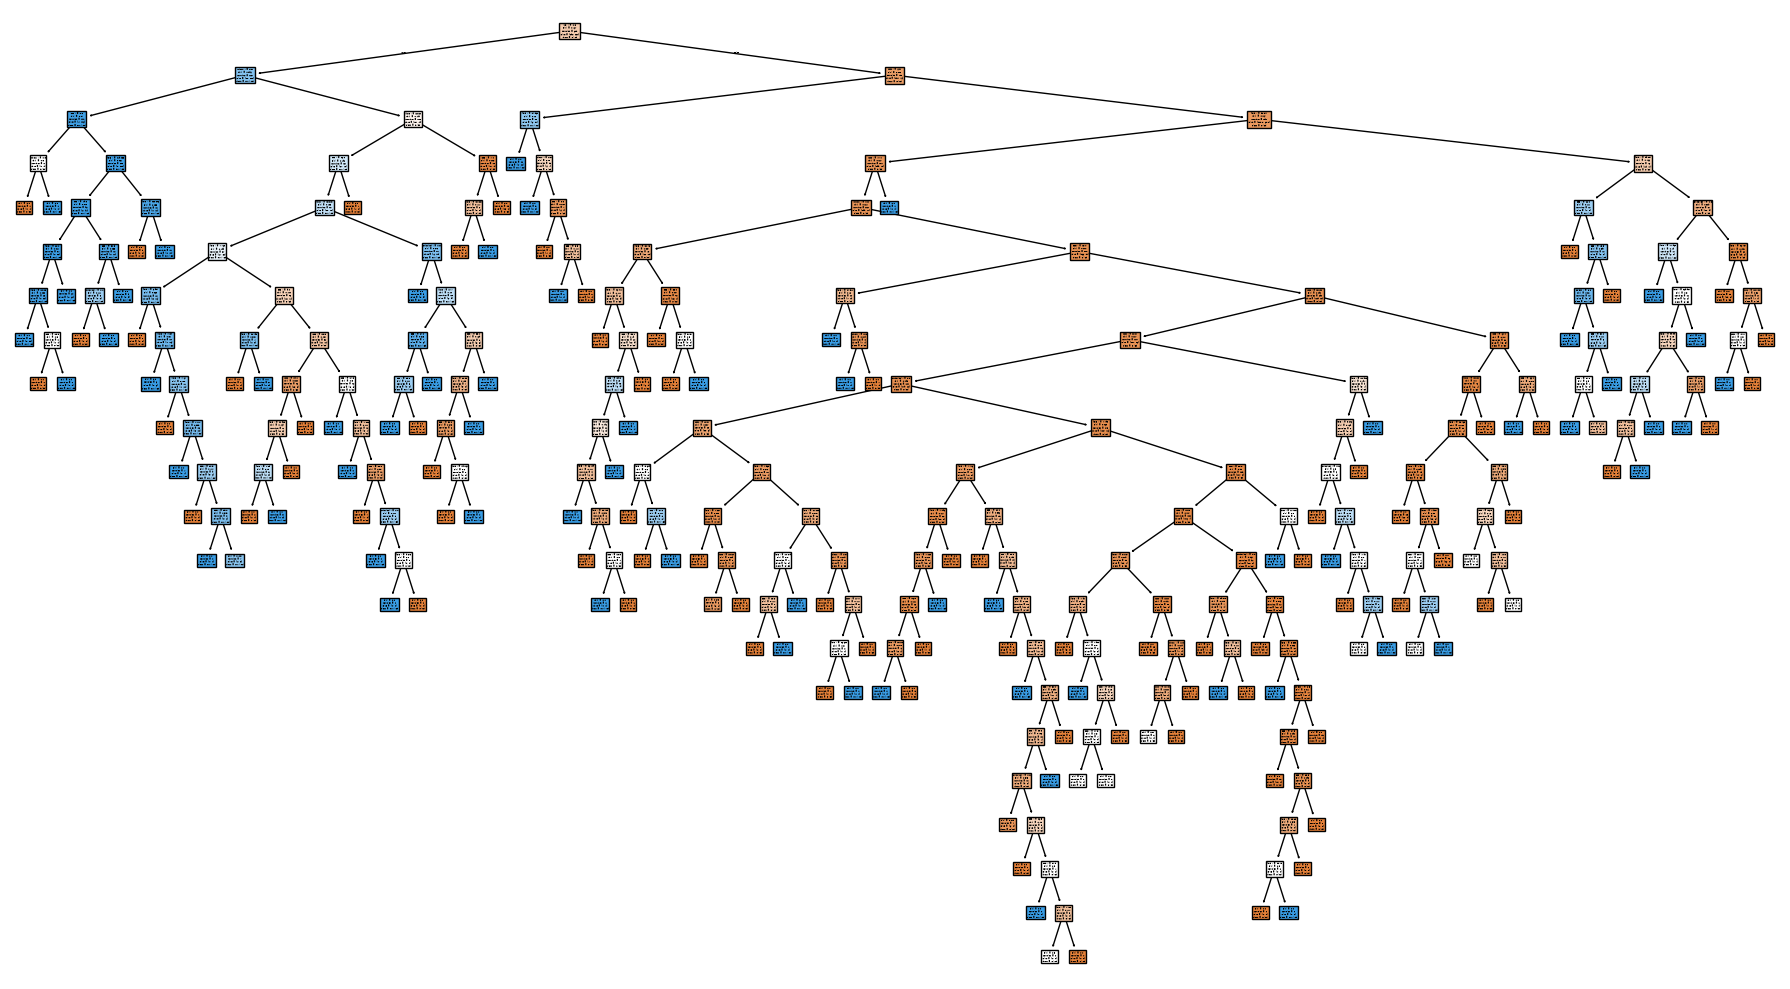

In [29]:
from sklearn.tree import plot_tree
plt.figure(figsize=(18,10))
plot_tree(
    model,
    feature_names=X.columns,
    class_names=["Died","Survived"],
    filled=True
)
plt.tight_layout()
plt.show()

In [30]:
from sklearn.ensemble import RandomForestClassifier
from sklearn.datasets import make_classification

rf = RandomForestClassifier(
   n_estimators=201,
    oob_score=True
)

rf.fit(X_train, y_train)
y_pred=rf.predict(X_test)

print(accuracy_score(y_test,y_pred))
print(rf.oob_score_)

0.7761194029850746
0.8041733547351525


In [31]:
# aboe case is better because training testing accuracy not much difference

titanic.shape

(891, 15)

In [32]:
# Bagging classifier

from sklearn.ensemble import BaggingClassifier

base_model=DecisionTreeClassifier()

bagging= BaggingClassifier(
   base_model,n_estimators=201
)
bagging.fit(X_train,y_train)

from sklearn.metrics import accuracy_score
y_pred=bagging.predict(X_test)
y_pred_train=bagging.predict(X_train)
print(accuracy_score(y_test,y_pred))

0.7723880597014925


In [33]:
from sklearn.linear_model import LogisticRegression

base_model=LogisticRegression(max_iter=1000)

bagging= BaggingClassifier(
   base_model,n_estimators=201
)
bagging.fit(X_train,y_train)

from sklearn.metrics import accuracy_score
y_pred=bagging.predict(X_test)
y_pred_train=bagging.predict(X_train)
print(accuracy_score(y_test,y_pred))

0.7947761194029851
